# Examen Práctico PIA

## Importar librerias

In [106]:
# AI Model
from tensorflow.keras import layers
from tensorflow.keras.models import Model
import tensorflow as tf

# Graphic
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Dataset from directory
from tensorflow.keras.preprocessing import image_dataset_from_directory

# Download file online
import gdown

# Image file processing
from PIL import Image

# Data augmentation
import albumentations as A
import cv2

# Others
import numpy as np
import random
import os

## Inicializar semillas

In [107]:
# Me ha parecido buena idea establecer semillas para evitar aleatoriedad
# y que los datos anotados en las observaciones sean consistentes
def fijar_semillas(seed=42):
    # Semilla para Python nativo
    random.seed(seed)

    # Semilla para Numpy
    np.random.seed(seed)

    # Semilla para TensorFlow
    tf.random.set_seed(seed)

fijar_semillas(42)

# Apartados Examen:

## A - Datasets

In [108]:
# Si está comentado quita el comentario cuando vayas a ejecutarlo, quería poder lanzar el código
# entero de golpe y esta linea me estaba parando el flujo de ejecución
!unzip -q {'images_de_tartas.zip'} -d /content/dataset_tartas

In [109]:
# Directorios base y entrenamiento/validacion
data_root = '/content/dataset_tartas/'
train_root = os.path.join(data_root, 'entrenamiento')
val_root = os.path.join(data_root, 'validacion')

In [110]:
def get_imagenes():
  IMG_SIZE = (320,256)
  BATCH_SIZE = 32

  # Dataset de entrenamiento
  train_ds_raw = tf.keras.utils.image_dataset_from_directory(
      train_root,
      image_size=IMG_SIZE,
      batch_size=BATCH_SIZE
  )

  # Dataset de validación
  val_ds_raw = tf.keras.utils.image_dataset_from_directory(
      val_root,
      image_size=IMG_SIZE,
      batch_size=BATCH_SIZE
  )

  return train_ds_raw, val_ds_raw

In [111]:
# Asignamos las variables usando el método
train_ds_raw, val_ds_raw = get_imagenes()

# Guardamos los nombres de las clases
class_names = np.array(train_ds_raw.class_names)

Found 480 files belonging to 3 classes.
Found 120 files belonging to 3 classes.


In [112]:
# Visualizar imagenes
def view_image(ds):
    print(f"Clases en dataset: {class_names}")

    plt.figure(figsize=(10, 10))
    for images, labels in ds.take(1):
      for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

Clases en dataset: ['cheesecake' 'chocolate_cake' 'red_velvet_cake']


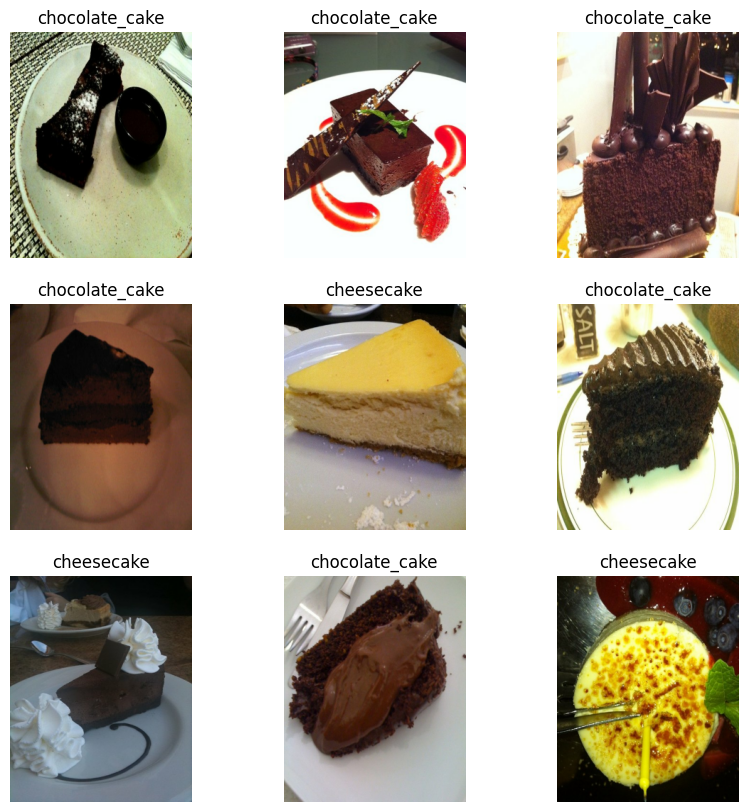

In [113]:
view_image(train_ds_raw)

In [114]:
def scaling_normalization(image, label):
    image = tf.cast(image/255., tf.float32)
    return image, label

In [115]:
# Normalización de los datasets
train_ds = train_ds_raw.map(scaling_normalization)
validation_ds = val_ds_raw.map(scaling_normalization)

## B - Arquitectura

In [116]:
IMG_SHAPE = (320,256,3)

def get_model_basico():
  input = layers.Input(shape=IMG_SHAPE)

  x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(input)
  x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(x)
  x = layers.MaxPooling2D()(x)

  x = layers.Conv2D(64, (5, 5), padding='same', strides=2, activation='relu')(x)
  x = layers.MaxPooling2D()(x)

  x = layers.Conv2D(128, (7, 7), padding='same', activation='relu')(x)
  x = layers.Conv2D(128, (7, 7), padding='same', activation='relu')(x)
  x = layers.GlobalAveragePooling2D()(x)

  x = layers.Dense(64, activation='relu')(x)
  x = layers.Dense(32, activation='relu')(x)

  output = layers.Dense(3, 'softmax')(x)

  model = Model(inputs=[input], outputs=[output])

  return model

In [117]:
# Cargamos el modelo y lo analizamos
model_basico = get_model_basico()
model_basico.summary()

Model: "functional_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_34 (InputLayer)     │ (None, 320, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1514 (Conv2D)            │ (None, 320, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1515 (Conv2D)            │ (None, 320, 256, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_68 (MaxPooling2D) │ (None, 160, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1516 (Conv2D)            │ (None, 80, 64, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_69 (MaxPooling2D) │ (None, 40, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1517 (Conv2D)            │ (None, 40, 32, 128)    │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1518 (Conv2D)            │ (None, 40, 32, 128)    │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_18     │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_52 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_53 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,276,323 (4.87 MB)

 Trainable params: 1,276,323 (4.87 MB)

 Non-trainable params: 0 (0.00 B)

## C - Entrenamiento / Gráficas

In [118]:
# Compilamos el modelo basico
model_basico.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Lo entrenamos y nos guardamos el history
history_basico = model_basico.fit(
    train_ds,
    epochs=10,
    validation_data=validation_ds,
    verbose=1
)

Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 33s 816ms/step - accuracy: 0.3012 - loss: 1.1198 - val_accuracy: 0.3333 - val_loss: 1.0950
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 190ms/step - accuracy: 0.3373 - loss: 1.0825 - val_accuracy: 0.4583 - val_loss: 1.0715
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 163ms/step - accuracy: 0.5015 - loss: 1.0451 - val_accuracy: 0.4333 - val_loss: 1.0628
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 162ms/step - accuracy: 0.5061 - loss: 1.0191 - val_accuracy: 0.3417 - val_loss: 1.0967
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 170ms/step - accuracy: 0.3706 - loss: 1.0850 - val_accuracy: 0.4000 - val_loss: 1.0871
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 168ms/step - accuracy: 0.4347 - loss: 1.0714 - val_accuracy: 0.4750 - val_loss: 1.0492
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 160ms/step - accuracy: 0.4781 - loss: 1.0056 - val_accuracy: 0.4417 - val_loss: 1.0180
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 160ms/step - accuracy: 0.4786 - loss: 1.0309 - val_accuracy: 0

In [139]:
def plot_history(history):
    # Configuramos el estilo
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

    # Extraemos el último valor en loss/accuracy redondeado a 4 decimales
    last_acc = history.history['accuracy'][-1]
    last_val_acc = history.history['val_accuracy'][-1]
    last_loss = history.history['loss'][-1]
    last_val_loss = history.history['val_loss'][-1]

    # Gráfico de accuracy
    ax1.plot(history.history['accuracy'], label=f'Train Accuracy ({last_acc:.4f})')
    ax1.plot(history.history['val_accuracy'], label=f'Val Accuracy ({last_val_acc:.4f})')

    # Forzar saltos de pasos a 0.1 y epocas a 1
    ax1.yaxis.set_major_locator(ticker.MultipleLocator(0.1))
    ax1.xaxis.set_major_locator(ticker.MultipleLocator(1))

    ax1.set_title('Model Accuracy', fontsize=14)
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Accuracy')
    ax1.legend(loc='lower right')
    ax1.set_ylim([0, 1]) # Accuracy entre 0 y 1
    ax1.set_xlim(left=0)   # Fuerzo el eje X para empezar en 0
    ax1.grid(True, alpha=0.3)

    # 2. Gráfico de loss
    ax2.plot(history.history['loss'], label=f'Train Loss ({last_loss:.4f})')
    ax2.plot(history.history['val_loss'], label=f'Val Loss ({last_val_loss:.4f})')

    # Forzar saltos epocas a 1
    # ax2.yaxis.set_major_locator(ticker.MultipleLocator(0.05))
    ax2.xaxis.set_major_locator(ticker.MultipleLocator(1))

    ax2.set_title('Model Loss', fontsize=14)
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Loss')
    ax2.legend(loc='lower right')
    ax2.set_ylim(bottom=0) # Fuerza el eje Y a empezar en 0
    ax2.set_xlim(left=0)   # Fuerza el eje X a empezar en 0
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

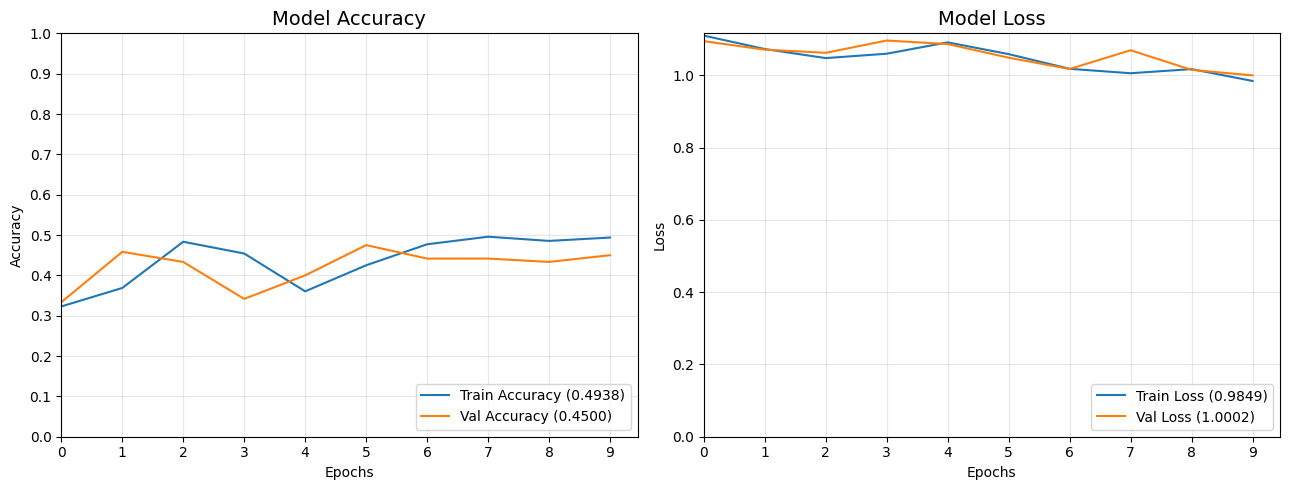

In [140]:
# Visualizamos el gráfico
plot_history(history_basico)

## D - Transferencia

In [120]:
def get_model_transferencia(n_capas_densas, n_neuronas_capas_densas):
    # Modelo base
    base_model = tf.keras.applications.InceptionV3(
        input_shape=IMG_SHAPE,
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False # Congelamos

    # Preprocesado
    preprocess_input = tf.keras.applications.inception_v3.preprocess_input

    input = layers.Input(shape=IMG_SHAPE)
    x = preprocess_input(input) # Capa preprocesado
    x = base_model(x, training=False) # Añadimos base model
    x = layers.GlobalAveragePooling2D()(x)

    # Capas densas dinámicas
    for i in range(n_capas_densas):
        x = layers.Dense(n_neuronas_capas_densas[i], activation='relu')(x)

    # Capa de salida softmax para clasificación multiclase
    output = layers.Dense(3, activation='softmax')(x)

    model_tl = Model(inputs=[input], outputs=[output])

    return model_tl

## E - Transferencia de Conocimiento

In [121]:
def model_train(model, train_dataset):
  # He añadido el parametro train_dataset para reutilizar este
  # método en el último ejercicio con aumento de datos
  model.compile(
      optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
      loss='sparse_categorical_crossentropy',
      metrics=['accuracy']
  )

  history = model.fit(
      train_dataset,
      epochs=10,
      validation_data=val_ds_raw,
      verbose=1
  )
  return history

### Modelo 1

In [122]:
model_tl_1 = get_model_transferencia(1, [8])
history_tl_1 = model_train(model_tl_1, train_ds_raw)
# model_tl_1.summary()

Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.3567 - loss: 1.1028 - val_accuracy: 0.4917 - val_loss: 1.0299
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 131ms/step - accuracy: 0.5572 - loss: 0.9649 - val_accuracy: 0.6167 - val_loss: 0.9273
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 133ms/step - accuracy: 0.6017 - loss: 0.8816 - val_accuracy: 0.6583 - val_loss: 0.8663
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step - accuracy: 0.6510 - loss: 0.8271 - val_accuracy: 0.6750 - val_loss: 0.8368
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 135ms/step - accuracy: 0.6727 - loss: 0.7722 - val_accuracy: 0.7250 - val_loss: 0.7774
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 148ms/step - accuracy: 0.7163 - loss: 0.7325 - val_accuracy: 0.7167 - val_loss: 0.7554
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step - accuracy: 0.7456 - loss: 0.6911 - val_accuracy: 0.7417 - val_loss: 0.7272
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 135ms/step - accuracy: 0.7972 - loss: 0.6203 - val_accuracy: 0.73

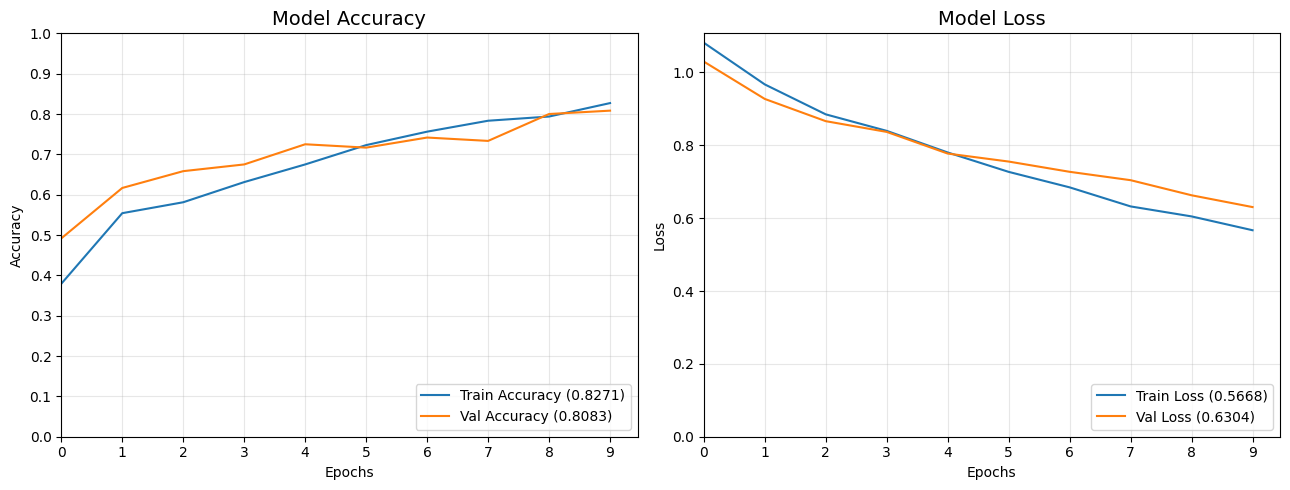

In [123]:
plot_history(history_tl_1)

### Modelo 2 ⭐

In [124]:
model_tl_2 = get_model_transferencia(2, [8, 16])
history_tl_2 = model_train(model_tl_2, train_ds_raw)
# model_tl_2.summary()

Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 26s 907ms/step - accuracy: 0.3670 - loss: 1.1029 - val_accuracy: 0.5500 - val_loss: 0.9726
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - accuracy: 0.4955 - loss: 0.9717 - val_accuracy: 0.6667 - val_loss: 0.8406
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - accuracy: 0.6265 - loss: 0.8384 - val_accuracy: 0.7083 - val_loss: 0.7505
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 130ms/step - accuracy: 0.7192 - loss: 0.7486 - val_accuracy: 0.7417 - val_loss: 0.6752
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step - accuracy: 0.7598 - loss: 0.6624 - val_accuracy: 0.7333 - val_loss: 0.6276
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 148ms/step - accuracy: 0.7498 - loss: 0.6310 - val_accuracy: 0.7833 - val_loss: 0.6130
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 141ms/step - accuracy: 0.8104 - loss: 0.5522 - val_accuracy: 0.7250 - val_loss: 0.5945
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 133ms/step - accuracy: 0.8415 - loss: 0.4954 - val_accuracy: 0

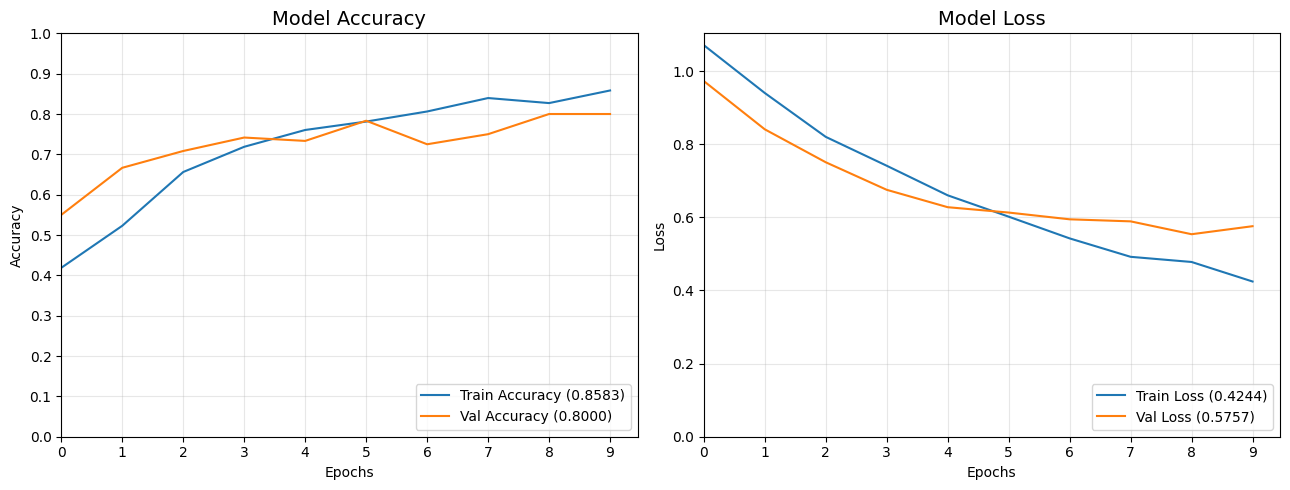

In [125]:
plot_history(history_tl_2)

### Modelo 3

In [126]:
model_tl_3 = get_model_transferencia(3, [8, 16, 32])
history_tl_3 = model_train(model_tl_3, train_ds_raw)
# model_tl_3.summary()

Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 26s 894ms/step - accuracy: 0.3561 - loss: 1.0846 - val_accuracy: 0.5417 - val_loss: 0.9736
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 139ms/step - accuracy: 0.5774 - loss: 0.9413 - val_accuracy: 0.6667 - val_loss: 0.7886
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 130ms/step - accuracy: 0.6884 - loss: 0.7454 - val_accuracy: 0.7083 - val_loss: 0.6701
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step - accuracy: 0.7607 - loss: 0.6205 - val_accuracy: 0.7250 - val_loss: 0.5976
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 131ms/step - accuracy: 0.8247 - loss: 0.4876 - val_accuracy: 0.6750 - val_loss: 0.6801
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step - accuracy: 0.8130 - loss: 0.4692 - val_accuracy: 0.7500 - val_loss: 0.6338
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step - accuracy: 0.8390 - loss: 0.4095 - val_accuracy: 0.7583 - val_loss: 0.6026
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 146ms/step - accuracy: 0.8991 - loss: 0.3253 - val_accuracy: 0

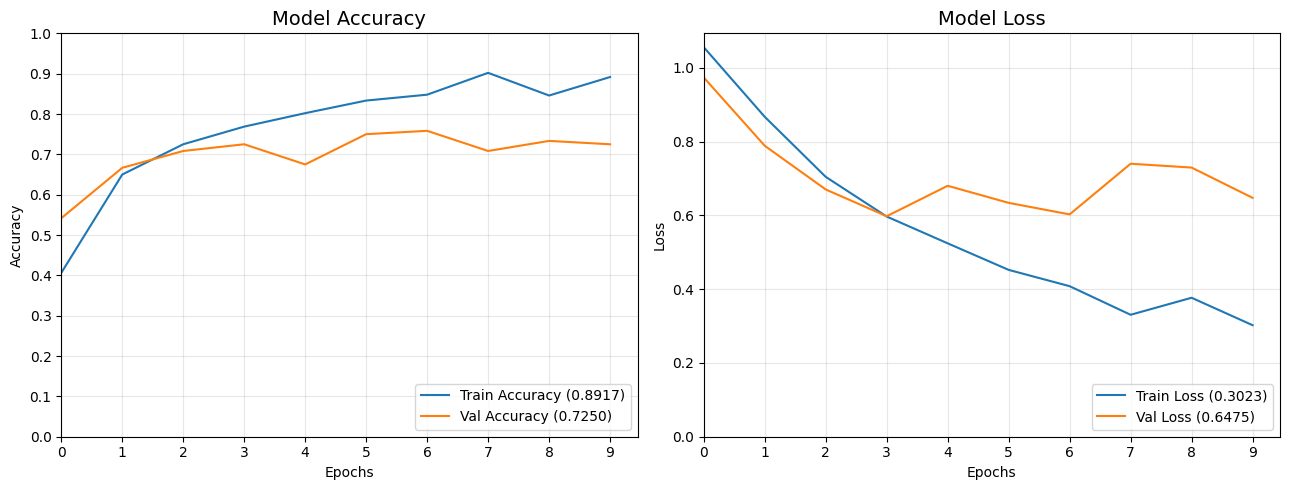

In [127]:
plot_history(history_tl_3)

### Modelo 4

In [128]:
model_tl_4 = get_model_transferencia(4, [8, 16, 32, 64])
history_tl_4 = model_train(model_tl_4, train_ds_raw)
# model_tl_4.summary()

Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.3392 - loss: 1.0978 - val_accuracy: 0.5250 - val_loss: 1.0607
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 134ms/step - accuracy: 0.5023 - loss: 1.0341 - val_accuracy: 0.6333 - val_loss: 0.9459
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 133ms/step - accuracy: 0.6850 - loss: 0.8681 - val_accuracy: 0.7083 - val_loss: 0.7519
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 213ms/step - accuracy: 0.7663 - loss: 0.6666 - val_accuracy: 0.6750 - val_loss: 0.6980
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 154ms/step - accuracy: 0.7618 - loss: 0.5754 - val_accuracy: 0.7000 - val_loss: 0.6171
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 141ms/step - accuracy: 0.8428 - loss: 0.4277 - val_accuracy: 0.7500 - val_loss: 0.6076
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 135ms/step - accuracy: 0.8654 - loss: 0.3966 - val_accuracy: 0.7250 - val_loss: 0.6284
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 149ms/step - accuracy: 0.8730 - loss: 0.3447 - val_accuracy: 0.72

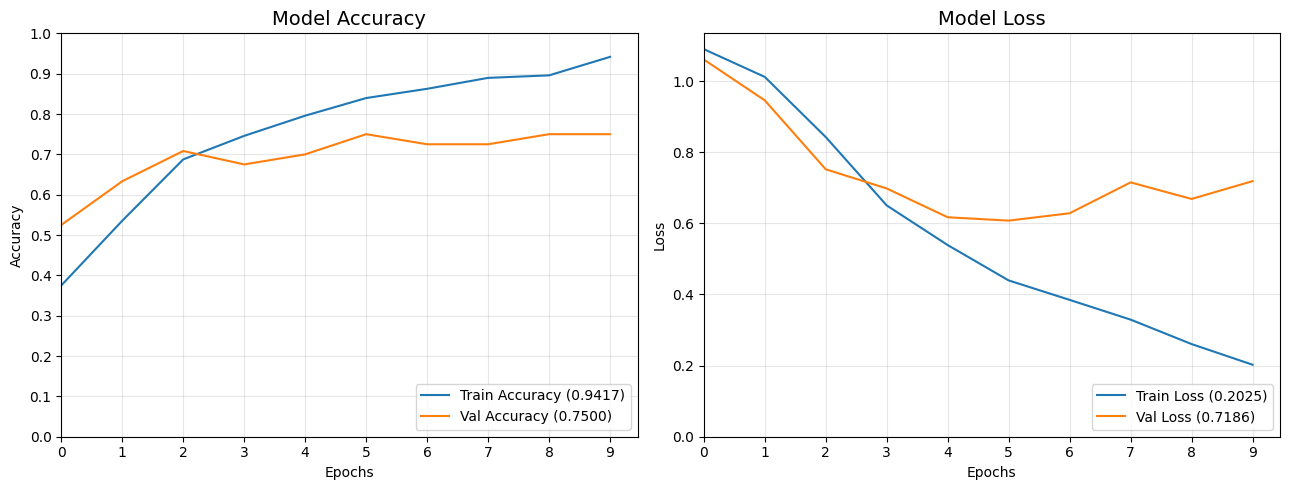

In [129]:
plot_history(history_tl_4)

### Observaciones
De los cuatro modelos entrenados el que mejor rendimiento ha dado ha sido el **Modelo 2** con las siguientes métricas en datos de validación:

*   accuracy: 0.8000
*   loss: 0.5757

En contraste con el modelo del apartado C que tenía las siguientes métricas en validación:

*   accuracy: 0.4500
*   loss: 1.0002

Con estos datos podemos concluir que el nuevo modelo ofrece un mejor rendimiento ya que hemos aumentado la precisión en un 55% y hemos disminuido la tasa de errores a casi la mitad.

## F - Aumento de Datos

### Transformaciones

In [144]:
# Implementamos la rutina de transformaciones
transforms = A.Compose([
    A.Rotate(limit=20, p=0.2),
    A.RandomBrightnessContrast(p=0.3),
    A.HorizontalFlip(p=0.4)
])

In [145]:
# Implementamos la función de aumento de datos
# El dataset esta ya organizado en lotes, por lo que implementamos una rutina para que,
# dado un lote, aplique la transformación a cada una de las imágenes
def augment_image_batch(images, labels):
    def augment_single_image(img, lbl):
        # Convertir imagen a numpy
        img = tf.cast(img, tf.uint8).numpy()

        # Aplicar transformaciones con Albumentations
        augmented = transforms(image=img)
        aug_img = augmented["image"]

        return aug_img, lbl

    # Usa `tf.map_fn` para procesar cada imagen y etiqueta en el lote
    augmented_data = tf.map_fn(
        lambda x: augment_single_image(x[0], x[1]),
        (images, labels),
        fn_output_signature=(tf.float32, tf.int32)
    )

    # Separar imágenes y etiquetas
    augmented_images, augmented_labels = augmented_data

    return augmented_images, augmented_labels

In [146]:
# Aplicamos la transformación al dataset de entrenamiento
train_ds_aug_raw = train_ds_raw.map(
    lambda x, y: tf.py_function(
        func=augment_image_batch,
        inp=[x, y],
        Tout=(tf.float32, tf.int32)
    )
)

In [147]:
train_ds_aug_raw

<_MapDataset element_spec=(TensorSpec(shape=<unknown>, dtype=tf.float32, name=None), TensorSpec(shape=<unknown>, dtype=tf.int32, name=None))>

In [148]:
# Reestablecer el tamaño de las imágenes
def set_shapes(images, labels):
    images.set_shape([None, 320, 256, 3])
    labels.set_shape([None])
    return images, labels

train_ds_aug_raw = train_ds_aug_raw.map(set_shapes)

In [149]:
for images, labels in train_ds_aug_raw.take(1):
    print(f"Forma de las imágenes: {images.shape}")
    print(f"Forma de las etiquetas: {labels.shape}")

Forma de las imágenes: (32, 320, 256, 3)
Forma de las etiquetas: (32,)


Clases en dataset: ['cheesecake' 'chocolate_cake' 'red_velvet_cake']


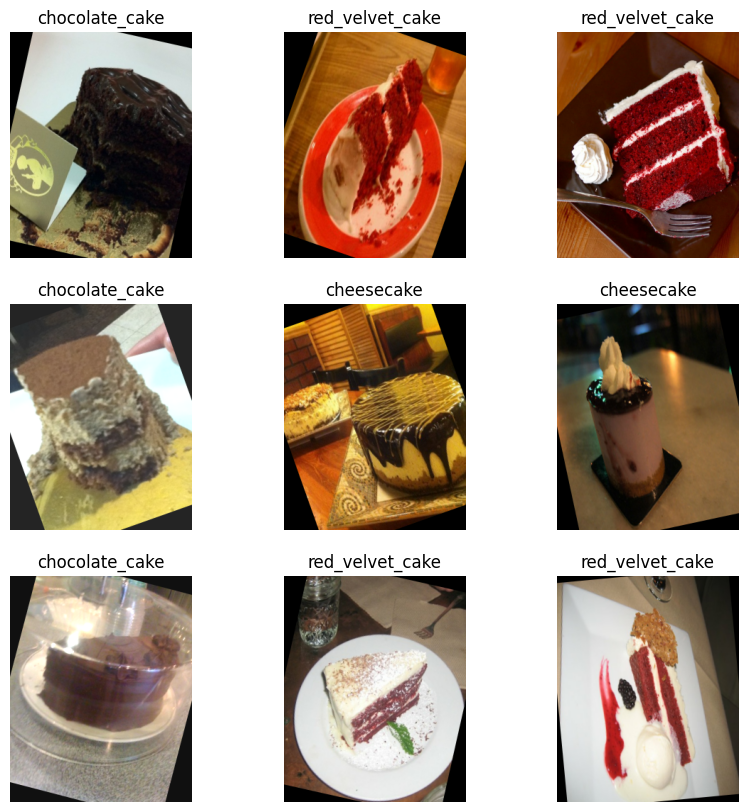

In [150]:
# Visualizamos imágenes entrenamiento: con aumento de datos
view_image(train_ds_aug_raw)

### Entrenamiento

In [137]:
# Usamos la misma configuración que el Model 2, y luego lo nutrimos con el
# dataset aumentado con transformaciones
model_tl_aug = get_model_transferencia(2, [8, 16])
history_tl_aug = model_train(model_tl_aug, train_ds_aug_raw)
# model_tl_2.summary()

Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - accuracy: 0.3747 - loss: 1.1238 - val_accuracy: 0.5250 - val_loss: 0.9702
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 332ms/step - accuracy: 0.5337 - loss: 0.9493 - val_accuracy: 0.5500 - val_loss: 0.9104
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 285ms/step - accuracy: 0.5257 - loss: 0.8858 - val_accuracy: 0.6000 - val_loss: 0.8334
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 281ms/step - accuracy: 0.5995 - loss: 0.8203 - val_accuracy: 0.5750 - val_loss: 0.9031
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 309ms/step - accuracy: 0.6592 - loss: 0.8099 - val_accuracy: 0.6750 - val_loss: 0.7572
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 279ms/step - accuracy: 0.6856 - loss: 0.7323 - val_accuracy: 0.7167 - val_loss: 0.7382
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 339ms/step - accuracy: 0.7061 - loss: 0.6911 - val_accuracy: 0.7833 - val_loss: 0.6556
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 238ms/step - accuracy: 0.7832 - loss: 0.5949 - val_accuracy: 0.7

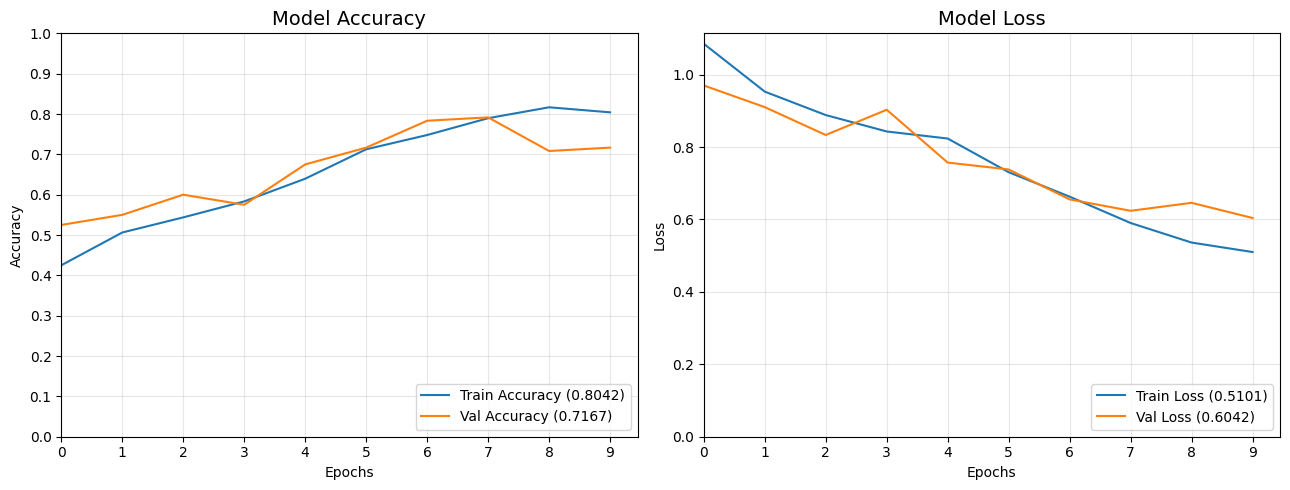

In [138]:
plot_history(history_tl_aug)

### Observaciones
Este modelo con aumento de datos ha resultado en unas métricas ligeramente inferiores al Modelo 2 del apartado E

Modelo con Aumento de datos
*   accuracy: 0.7167 ~(-8%)
*   loss: 0.6042 ~(-3%)

Modelo con Transferencia de conocimiento
*   accuracy: 0.8000
*   loss: 0.5757

Nos quedamos con el Modelo 2 que hace uso únicamente de la transferencia de conocimiento